ASSIGNMENT-7

Q1.Write a program to sharpen the input image using:
1. Laplacian filter

Saving IMG.JPG to IMG.JPG


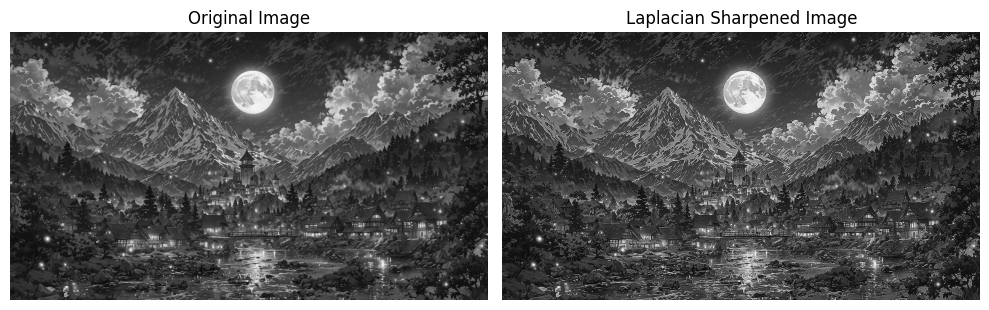

In [6]:

import cv2
import numpy as np
import matplotlib.pyplot as plt

from google.colab import files

# Upload image
uploaded = files.upload()

# Get uploaded image filename
filename = list(uploaded.keys())[0]

# Read image in grayscale
img = cv2.imread(filename, 0)

# Apply Laplacian filter
laplacian = cv2.Laplacian(img, cv2.CV_64F)

# Sharpen image
sharpened = img.astype(np.float64) - laplacian

# Convert to uint8
sharpened = np.clip(sharpened, 0, 255).astype(np.uint8)

# Display original and sharpened images
plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(img, cmap="gray")
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(sharpened, cmap="gray")
plt.title("Laplacian Sharpened Image")
plt.axis("off")

plt.tight_layout()
plt.show()


2. Gradient operators of Sobel and Canny edge detector

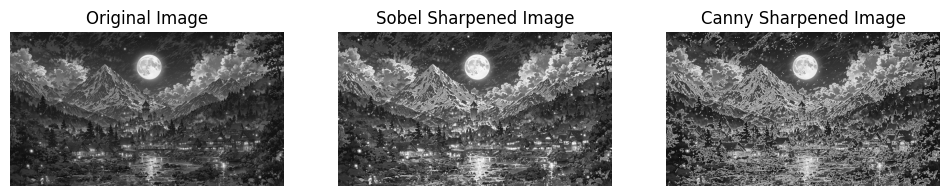

In [7]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

img = cv2.imread("IMG.JPG", 0)

# Sobel operator
sobel_x = cv2.Sobel(img, cv2.CV_64F, 1, 0, ksize=3)
sobel_y = cv2.Sobel(img, cv2.CV_64F, 0, 1, ksize=3)

sobel = cv2.magnitude(sobel_x, sobel_y)
sobel = np.uint8(255 * sobel / np.max(sobel))

sobel_sharp = cv2.add(img, sobel)

# Canny edge detector
canny = cv2.Canny(img, 100, 200)

canny_sharp = cv2.add(img, canny)

plt.figure(figsize=(12,5))

plt.subplot(1,3,1)
plt.imshow(img, cmap="gray")
plt.title("Original Image")
plt.axis("off")

plt.subplot(1,3,2)
plt.imshow(sobel_sharp, cmap="gray")
plt.title("Sobel Sharpened Image")
plt.axis("off")

plt.subplot(1,3,3)
plt.imshow(canny_sharp, cmap="gray")
plt.title("Canny Sharpened Image")
plt.axis("off")

plt.show()

3. Unsharp masking. To obtain blurred image, use the Gaussian filter of size 5x5 and sigma= 3.

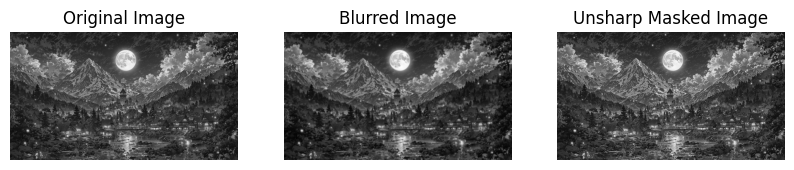

In [8]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

img = cv2.imread("IMG.JPG", 0)

# Apply Gaussian blur
blur = cv2.GaussianBlur(img, (5,5), 3)

# Create unsharp mask
mask = cv2.subtract(img, blur)

# Sharpen the image
sharpened = cv2.add(img, mask)

plt.figure(figsize=(10,5))

plt.subplot(1,3,1)
plt.imshow(img, cmap="gray")
plt.title("Original Image")
plt.axis("off")

plt.subplot(1,3,2)
plt.imshow(blur, cmap="gray")
plt.title("Blurred Image")
plt.axis("off")

plt.subplot(1,3,3)
plt.imshow(sharpened, cmap="gray")
plt.title("Unsharp Masked Image")
plt.axis("off")

plt.show()